# 6. Hybrid ARIMA-LSTM variants

One-step residuals versus multi-step ARIMA errors, and the validation scores of the three variants.

In [1]:
import sys
from pathlib import Path
CODE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_DIR))
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from src import config, experiment
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
TABLES = config.OUTPUT_DIR / "tables"
FIGS = config.FIGURE_DIR

In [2]:
summary = json.loads((config.METRIC_DIR / 'evaluation_summary.json').read_text())
{k: {'primary': v['primary_hybrid'], 'validation_mase': v['hybrid_validation_mase'],
     'error_growth_h1': v['error_growth_median_h1'], 'error_growth_h28': v['error_growth_median_h28']}
 for k, v in summary.items()}

{'m5': {'primary': 'hyb_z',
  'validation_mase': {'hyb_d': 0.716553590348006,
   'hyb_ms': 0.7475869079547072,
   'hyb_z': 0.6961069472633568},
  'error_growth_h1': 0.6926811176386349,
  'error_growth_h28': 1.0916726488629565},
 'rossmann': {'primary': 'hyb_ms',
  'validation_mase': {'hyb_d': 0.41404718441300015,
   'hyb_ms': 0.3655617595041672,
   'hyb_z': 0.4077622633333329},
  'error_growth_h1': 0.6553096568500363,
  'error_growth_h28': 1.1301797942955005}}

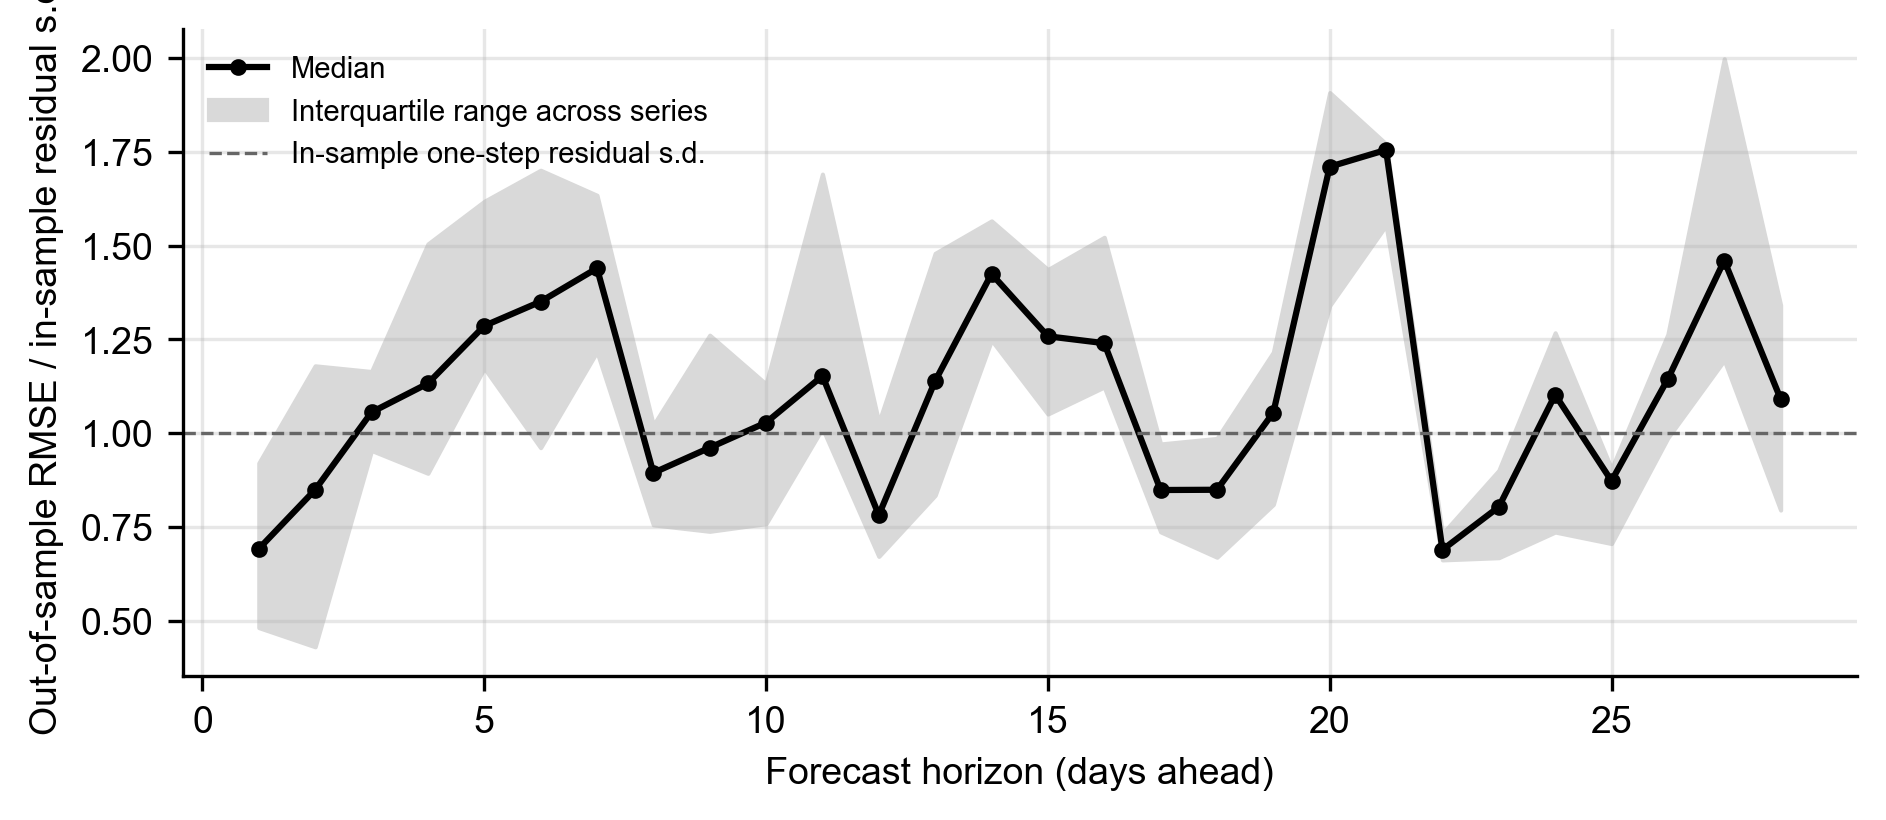

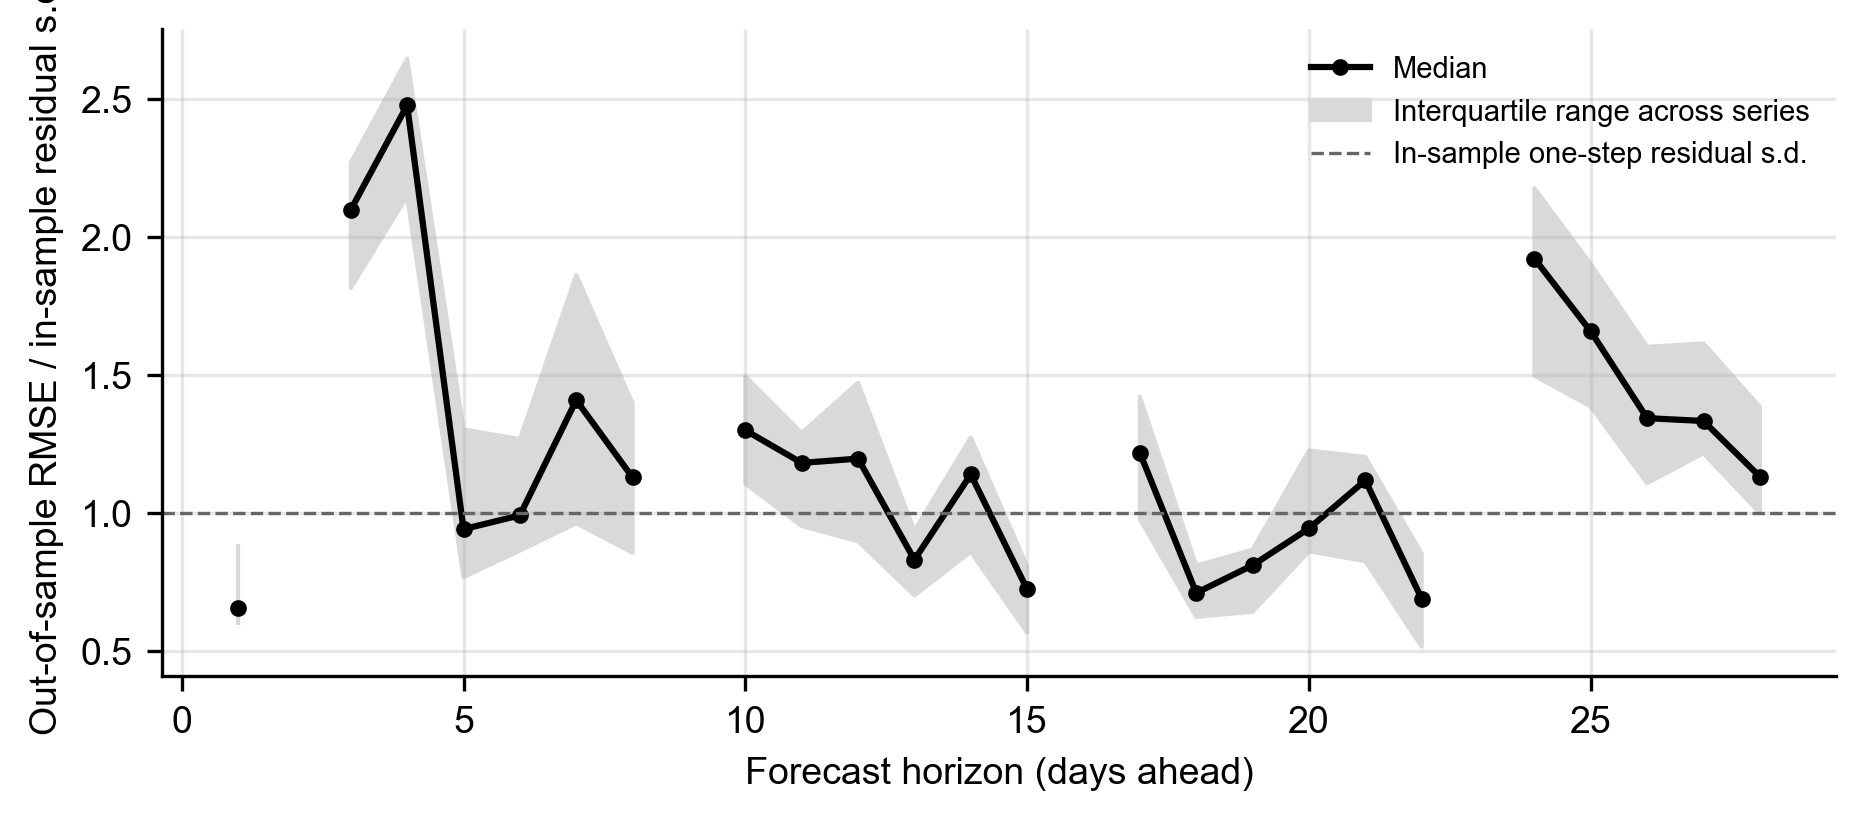

In [3]:
for name in ['m5', 'rossmann']:
    display(Image(filename=str(FIGS / f'res_{name}_error_growth.png'), width=800))